# RMTB's weight-space posterior variance

$$\mathrm{Var}_{\mathrm{bayes}}(x^*) = \sigma^2\, f(x^*)^\top\, \mathrm{mtx}^{-1}\, f(x^*)$$

Notebook 3 justified using `RMTB` alone from here on. This notebook
establishes and validates `RMTB`'s own posterior-variance formula -- the
foundation `krig_splines_clean.rmtb_uq.RMTBUQ` is built on, and everything
Notebooks 5-8 do with it.

This notebook uses the `cond(mtx) > 1e8` "numerically suspect" safety
line this project applies throughout, reproduces the
`mtx`/`full_jac_dict`/`full_hess` bookkeeping SMT exposes, and scopes
Test 2's route-independence claim carefully (Section 1.3).

## 1. Theoretical background

### 1.1 RMTB's own penalized regression

`RMTB` fits $f(x) = \Phi(x)\mathbf w$ -- a B-spline basis with
`num_ctrl_pts` control points per axis -- by minimizing

$$\|\Phi\mathbf w - y\|^2 + \mathbf w^\top H \mathbf w,$$

the same penalized-least-squares objective as every smoothing spline in
this project (Notebook 3, Section 1.1), with the single matrix $H$
playing the role that $\lambda$ and the roughness-penalty matrix play
together elsewhere.

### 1.2 The weight-space posterior variance

This project has used one Bayesian linear-Gaussian identity throughout
(Notebook 2, Section 1.4): whenever the posterior mean is a linear
operator $A$ applied to the data $y$, the posterior covariance is

$$\mathrm{Cov}(\mathbf w \mid y) = \sigma^2 A.$$

That identity applies directly here. The normal equations for Section
1.1's objective are

$$\mathrm{mtx}\cdot\mathbf w = \Phi^\top y, \qquad \mathrm{mtx} = \Phi^\top\Phi + H,$$

where $\mathrm{mtx}$ is `RMTB`'s own `.mtx` attribute -- confirmed
directly in Test 1, not assumed from the formula alone. So $A =
\mathrm{mtx}^{-1}$, and the posterior covariance of $\mathbf w$ is
$\sigma^2\,\mathrm{mtx}^{-1}$. The posterior variance of a prediction at
a new point $x^*$ then follows from the usual identity
$\mathrm{Var}(f(x^*)) = f(x^*)^\top\,\mathrm{Cov}(\mathbf w)\,f(x^*)$,
giving this notebook's central formula:

$$\mathrm{Var}_{\mathrm{bayes}}(x^*) = \sigma^2\, f(x^*)^\top\, \mathrm{mtx}^{-1}\, f(x^*).$$

**In plain terms**: the same "how much does the fit's own machinery
trust itself" idea used for every other model in this project, applied
to `RMTB`'s specific finite-basis-plus-energy-penalty structure instead
of a kernel.

### 1.3 What "two independent routes" means here, precisely

Test 2 below checks this formula's linear solve two ways -- a plain
`np.linalg.solve` and an SVD-regularized `np.linalg.lstsq` -- and treats
agreement between them as a Phase-F4-style independence check. **This
needs a precise caveat, stated here before the test, not after**: both
routes invert the *same* matrix, $\mathrm{mtx}$. So this checks that the
*solve itself* is numerically trustworthy regardless of which algorithm
performs it -- and that the two algorithms do not quietly agree on a
wrong answer when $\mathrm{mtx}$ is badly conditioned (a badly-conditioned
$\mathrm{mtx}$ makes the two algorithms diverge rather than quietly agree
on a wrong answer).
It is **not** a check that the formula in Section 1.2 is correct against
some independently-*derived* alternative. That stronger kind of check --
Proposition 6's dual/kernel-space route, a genuinely different algebraic
form of the same posterior -- is Notebook 5's job specifically, with its
own, separately-earned caveats.

A third candidate -- wiring a separately-written, RMTB-agnostic generic
Bayesian-ridge tool (`validation.RMTBUncertaintyWrapper`) to this same
$\Phi$/$H$/formula -- was tried and deliberately *not* kept as a
notebook test here. Traced down to LAPACK, its
`scipy.linalg.solve(assume_a="pos")` and `scipy.linalg.inv`'s automatic
structure detection both route through the identical Cholesky
factor-and-solve that `RMTBUQ` uses explicitly, so agreement between the
two is independent *code*, not an independent *algorithm* or
*derivation* -- it can only catch an implementation bug (a sign flip, a
transpose, an off-by-one in `edf`), which is a code-correctness
question, not a math/methodology one. That check now lives as a unit
test (`tests/test_rmtb_uncertainty_wrapper.py`), not a notebook cell, so
this notebook's tests stay focused on what it is for: this project's own
formulas, theorems, and assumptions.

## 2. Setup: shared datasets

Regular grid and random spacing, reusing this project's established 2-D
synthetic target ($\sin(3x_1)\cos(3x_2)$, $\sigma=0.05$, $[0,1]^2$,
Notebooks 2-3) and the established `RMTB` construction convention
(`order=4, approx_order=2, num_ctrl_pts=20, energy_weight=1e-2,
regularization_weight=1e-14, solver="dense-lu"`, Notebook 2 Test 3a), at
the $8\times8$ ($n=64$) resolution this project's own earlier RMTB-variance
exploration used.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from krig_splines_clean.rmtb_uq import RMTBUQ
from krig_splines_clean.polyharmonic import PolyharmonicSmoothingSpline

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 12,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "legend.fontsize": 9,
})
pd.set_option("display.float_format", lambda v: f"{v:.4e}")

XLIMITS = np.array([[0., 1.], [0., 1.]])
COND_SUSPECT_LINE = 1e8  # Important questions.md Q16/Q17
RMTB_KW = dict(xlimits=XLIMITS, order=4, approx_order=2, num_ctrl_pts=20,
               energy_weight=1e-2, regularization_weight=1e-14,
               solver="dense-lu", print_global=False)


def true_f2d(X1, X2):
    return np.sin(3 * X1) * np.cos(3 * X2)


def make_dataset(spacing, n_side=8, seed=1):
    rng = np.random.default_rng(seed)
    if spacing == "regular":
        g = np.linspace(0, 1, n_side)
        G1, G2 = np.meshgrid(g, g, indexing="ij")
        X = np.column_stack([G1.ravel(), G2.ravel()])
    else:
        X = rng.uniform(0, 1, size=(n_side * n_side, 2))
    y = true_f2d(X[:, 0], X[:, 1]) + 0.05 * rng.standard_normal(len(X))
    return X, y


datasets = {"regular": make_dataset("regular"), "random": make_dataset("random")}
models = {}
for spacing, (X, y) in datasets.items():
    m = RMTBUQ(**RMTB_KW)
    m.set_training_values(X, y)
    m.train()
    models[spacing] = m

pd.DataFrame([{"spacing": s, "n": len(X), "sigma2_hat": models[s].sigma2, "edf": models[s].edf}
              for s, (X, y) in datasets.items()]).set_index("spacing")


,n,sigma2_hat,edf
spacing,,,
regular,64,2.6632e-03,2.2899e+01
random,64,2.5664e-03,1.5680e+01


## Test 1 -- the mtx identity, reproduced from SMT's own attributes

**What this tests**: the basic bookkeeping claim everything else in this
notebook (and Notebook 5) depends on -- that SMT's own `model.mtx`
(exposed after training) really is $\Phi^\top\Phi+H$ for `RMTB`'s own
$\Phi$ (`model.full_jac_dict[0][0]`) and $H$ (`model.full_hess`), not just
conceptually but to the solver's own floating-point precision.

**Expected result**: machine precision agreement, on both spacings -- this
is reading off two already-computed attributes and checking they combine
the way SMT's own documentation says, not an approximation of any kind.

In [2]:
test1_rows = []
for spacing, m in models.items():
    Phi, _PhiT, _c = m.full_jac_dict[0]
    Phi = Phi.toarray()
    H = m.full_hess.toarray()
    mtx_reconstructed = Phi.T @ Phi + H
    err = np.max(np.abs(mtx_reconstructed - m.mtx.toarray()))
    test1_rows.append({"spacing": spacing, "mtx shape": m.mtx.shape,
                        "max|Phi^T Phi + H - mtx|": err})

pd.DataFrame(test1_rows).set_index("spacing")


,mtx shape,max|Phi^T Phi + H - mtx|
spacing,,
regular,"(400, 400)",1.3878e-17
random,"(400, 400)",8.8818e-16


**Confirmed, to float64 noise level, both spacings.** `max|\Phi^\top\Phi+H-\mathrm{mtx}|`
is `1.4e-17` (regular) / `8.9e-16` (random) -- SMT's own exposed attributes
combine exactly the way Section 1.2 assumed. Everything below builds on
this directly, not as an unstated assumption.

## Test 2 -- two independent solve algorithms, same matrix

**What this tests** (see Section 1.3 for the precise, limited claim this
supports): the same linear solve, $\mathrm{mtx}^{-1}f$, computed via plain
`np.linalg.solve` and via SVD-regularized `np.linalg.lstsq` -- a
numerical-robustness check on the solve itself, reported alongside
$\mathrm{cond}(\mathrm{mtx})$ so the agreement (or eventual disagreement)
has an explanation, not just a number.

**Expected result**: tight agreement at both training points (used for
$\mathbf w$ directly) and at a dense query grid (used for the variance
formula), since `RMTB`'s own `cond(mtx)` was already found safe
(`~2.5e4`-`~4.9e4`) across a wide case matrix in Notebook 3.

In [3]:
gq = np.linspace(0, 1, 60)
GQ1, GQ2 = np.meshgrid(gq, gq, indexing="ij")
Xq_dense = np.column_stack([GQ1.ravel(), GQ2.ravel()])

test2_rows = []
route_vars = {}
for spacing, m in models.items():
    X, y = datasets[spacing]
    mtx = m.mtx.toarray()
    Phi, PhiT, _c = m.full_jac_dict[0]
    rhs = np.asarray(PhiT @ y.reshape(-1, 1)).ravel()
    cond = np.linalg.cond(mtx)

    w_solve = np.linalg.solve(mtx, rhs)
    w_lstsq, *_ = np.linalg.lstsq(mtx, rhs, rcond=None)
    w_gap = np.max(np.abs(w_solve - w_lstsq))

    F = m._basis_row(Xq_dense)
    var_solve = m.sigma2 * np.sum(F * np.linalg.solve(mtx, F.T).T, axis=1)
    var_lstsq = m.sigma2 * np.sum(F * np.linalg.lstsq(mtx, F.T, rcond=None)[0].T, axis=1)
    var_gap = np.max(np.abs(var_solve - var_lstsq))
    route_vars[spacing] = dict(var_solve=var_solve, var_lstsq=var_lstsq)

    test2_rows.append({"spacing": spacing, "cond(mtx)": cond,
                        "max|w_solve - w_lstsq}|": w_gap,
                        "max|Var_solve - Var_lstsq| (dense query)": var_gap,
                        "% of variance range": 100 * var_gap / np.ptp(var_solve)})

pd.DataFrame(test2_rows).set_index("spacing")


,cond(mtx),max|w_solve - w_lstsq}|,max|Var_solve - Var_lstsq| (dense query),% of variance range
spacing,,,,
regular,2.5144e+04,2.2703e-11,4.0115e-16,2.4652e-11
random,2.6662e+04,9.5716e-12,2.2170e-15,1.0665e-11


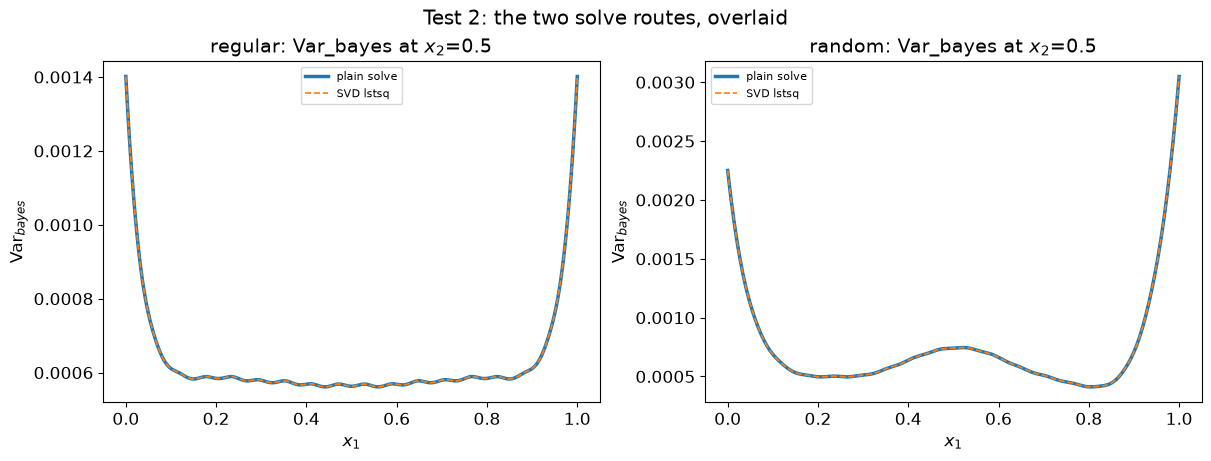

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
x2_fixed = 0.5
xq1d = np.linspace(0, 1, 300)
for ax, spacing in zip(axs, models):
    m = models[spacing]
    Xq_line = np.column_stack([xq1d, np.full_like(xq1d, x2_fixed)])
    mtx = m.mtx.toarray()
    F = m._basis_row(Xq_line)
    var_solve = m.sigma2 * np.sum(F * np.linalg.solve(mtx, F.T).T, axis=1)
    var_lstsq = m.sigma2 * np.sum(F * np.linalg.lstsq(mtx, F.T, rcond=None)[0].T, axis=1)
    ax.plot(xq1d, var_solve, lw=2.5, color="tab:blue", label="plain solve")
    ax.plot(xq1d, var_lstsq, lw=1.2, ls="--", color="tab:orange", label="SVD lstsq")
    ax.set_title(f"{spacing}: Var_bayes at $x_2$={x2_fixed}")
    ax.set_xlabel("$x_1$"); ax.set_ylabel("Var$_{bayes}$"); ax.legend(fontsize=8)
fig.suptitle("Test 2: the two solve routes, overlaid")
plt.show()


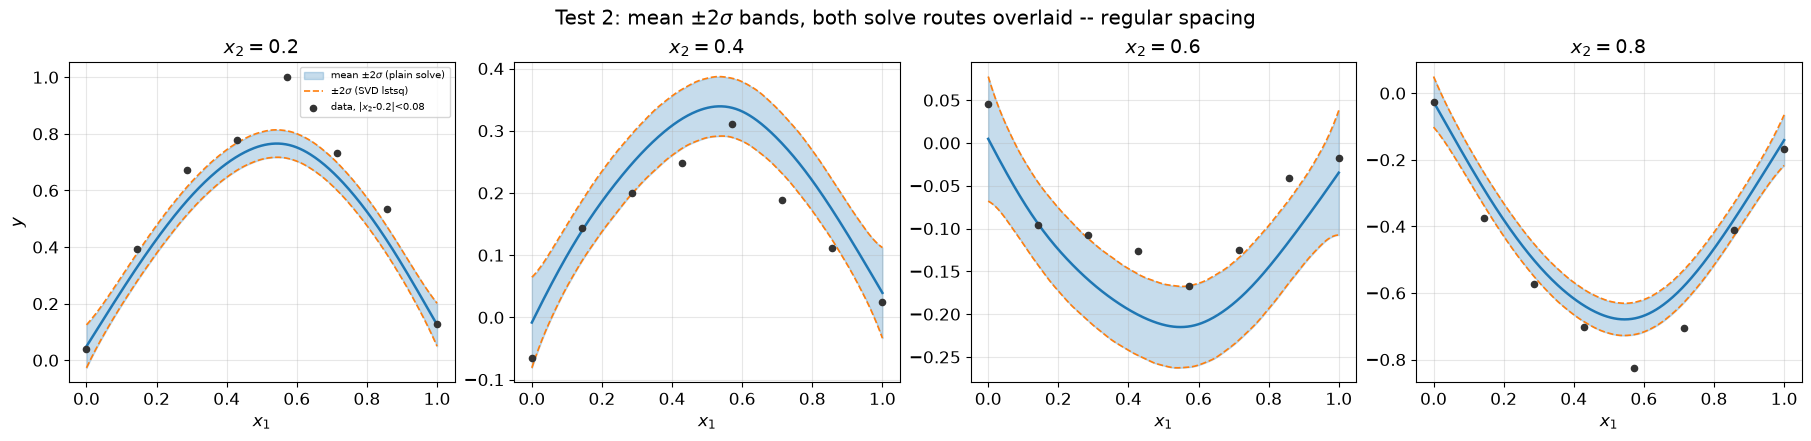

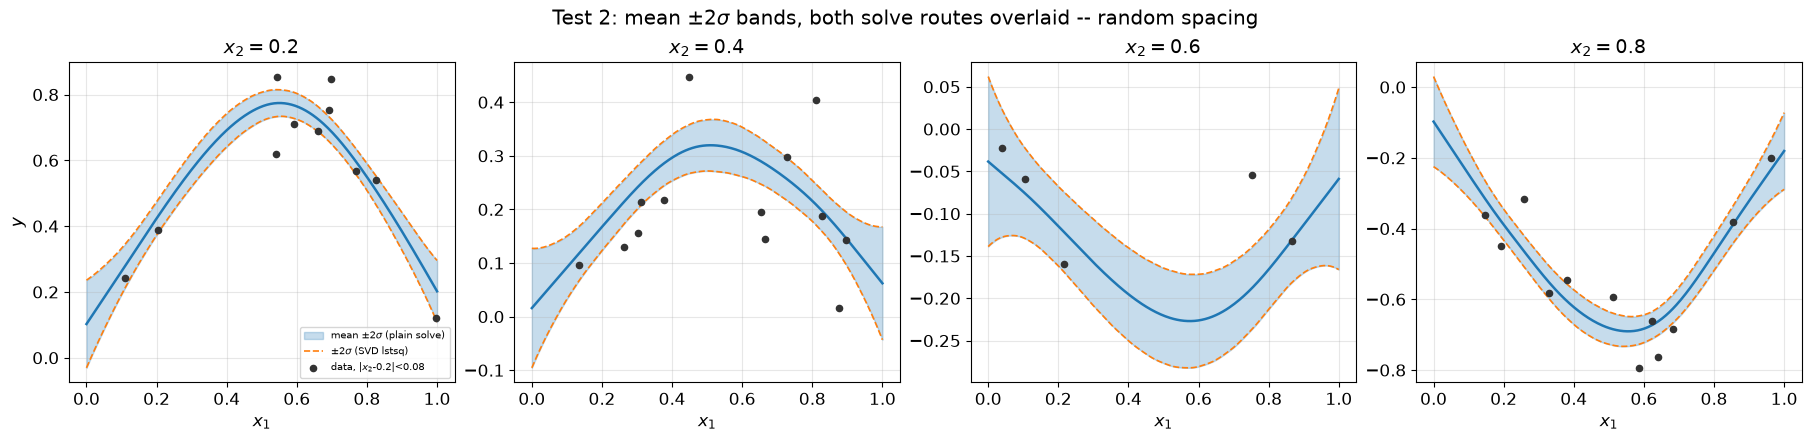

In [5]:
x2_slices_t2 = [0.2, 0.4, 0.6, 0.8]
near_tol_t2 = 0.08
xq1d_t2 = np.linspace(0, 1, 300)

for spacing, m in models.items():
    X, y = datasets[spacing]
    mtx = m.mtx.toarray()
    fig, axs = plt.subplots(1, 4, figsize=(18, 4.3), constrained_layout=True)
    for ax, x2_fixed in zip(axs, x2_slices_t2):
        near = np.abs(X[:, 1] - x2_fixed) < near_tol_t2
        Xq_line = np.column_stack([xq1d_t2, np.full_like(xq1d_t2, x2_fixed)])
        F = m._basis_row(Xq_line)
        mean_line = m.predict_values(Xq_line).ravel()
        var_solve = m.sigma2 * np.sum(F * np.linalg.solve(mtx, F.T).T, axis=1)
        var_lstsq = m.sigma2 * np.sum(F * np.linalg.lstsq(mtx, F.T, rcond=None)[0].T, axis=1)
        std_solve = np.sqrt(np.clip(var_solve, 0.0, None))
        std_lstsq = np.sqrt(np.clip(var_lstsq, 0.0, None))

        ax.fill_between(xq1d_t2, mean_line - 2 * std_solve, mean_line + 2 * std_solve,
                         color="tab:blue", alpha=0.25, label=r"mean $\pm2\sigma$ (plain solve)")
        ax.plot(xq1d_t2, mean_line - 2 * std_lstsq, color="tab:orange", lw=1.2, ls="--",
                 label=r"$\pm2\sigma$ (SVD lstsq)")
        ax.plot(xq1d_t2, mean_line + 2 * std_lstsq, color="tab:orange", lw=1.2, ls="--")
        ax.plot(xq1d_t2, mean_line, color="tab:blue", lw=1.8)
        ax.scatter(X[near, 0], y[near], s=20, color="0.2", zorder=5,
                    label=f"data, |$x_2$-{x2_fixed}|<{near_tol_t2}")
        ax.set_title(f"$x_2={x2_fixed}$")
        ax.set_xlabel("$x_1$")
        ax.grid(alpha=0.3)
    axs[0].set_ylabel("$y$")
    axs[0].legend(fontsize=7)
    fig.suptitle(f"Test 2: mean $\\pm2\\sigma$ bands, both solve routes overlaid -- {spacing} spacing")
    plt.show()

**Confirmed: the two routes agree far beyond what this notebook's safety
line requires**, both on the raw solve ($\mathbf w$: `2.3e-11` regular,
`9.6e-12` random) and on the resulting variance over a dense query grid
(`4.0e-16`/`2.2e-15`, `~1e-11`% of the variance surface's own range). With
`cond(mtx)` at `2.5e4`/`2.7e4` (Section 1.3's digits-retained rule predicts
`~11.6` trustworthy digits either way), this level of agreement is exactly
what the theory predicts, not a surprise -- and, per Section 1.3's own
caveat, confirms the *solve* is trustworthy here, not yet that the formula
itself is correct against an independent derivation (Notebook 5).

The mean $\pm2\sigma$ bands above, with the actual training data overlaid
at four slices per spacing, show the same agreement the way it will
actually be used: the SVD `lstsq` band's dashed edges sit essentially on
top of the plain-solve band's filled edges in every panel, on both
spacings -- the `~1e-11`% gap reported above is not visible at this scale,
which is exactly the point of also showing it numerically.

## Test 3 -- the condition number, checked and found safe before trusting any variance estimate

**What this tests**: not a new computation (Test 2 already reports
$\mathrm{cond}(\mathrm{mtx})$) but the explicit methodological step of
*checking it against this project's own safety line before relying on
anything above* -- trust is earned, not assumed. The digits-retained
rule,

$$\text{digits} \approx 16 - \log_{10}\big(\mathrm{cond}(\mathrm{mtx})\big),$$

turns the raw condition number into a concrete statement about how many
trustworthy digits the solve actually has left.

In [6]:
test3_rows = []
for spacing, m in models.items():
    cond = np.linalg.cond(m.mtx.toarray())
    digits = 16 - np.log10(cond)
    test3_rows.append({"spacing": spacing, "cond(mtx)": cond, "digits retained (approx)": digits,
                        "suspect (>1e8)": cond > COND_SUSPECT_LINE})

pd.DataFrame(test3_rows).set_index("spacing")


,cond(mtx),digits retained (approx),suspect (>1e8)
spacing,,,
regular,2.5144e+04,1.1600e+01,False
random,2.6662e+04,1.1574e+01,False


**Confirmed safe, both spacings**: `cond(mtx)` is `2.5e4` (regular) /
`2.7e4` (random), giving `~11.6` trustworthy digits by the digits-retained rule above --
comfortably under the `1e8` suspect line, and in the same narrow band
Notebook 3 found for `RMTB` across its own much larger 12-case matrix.
Test 2's agreement is therefore earned by a checked safety margin, not
assumed from the agreement alone.

## Test 4 -- data-gap acceptance test

**What this tests**: basic intuition (and every Kriging-style model this
project has built) says removing data from a region should make the model
specifically *less* confident there, not just overall. A circular gap
(radius $0.26$, centered at $(0.5,0.5)$) is cut out of each dataset's
training points, both models are refit, and `Var_bayes` at the gap's exact
center is compared before and after.

**Expected result**: `cond(mtx)` stays safe after removing data (fewer
points does not, by itself, break conditioning here), and the variance at
the gap center increases substantially -- this project's own earlier
exploration of this exact test found roughly a $3\times$ increase.

In [7]:
gap_radius = 0.26
gap_center = np.array([0.5, 0.5])

test4_rows = []
gap_models = {}
for spacing, m in models.items():
    X, y = datasets[spacing]
    dist = np.linalg.norm(X - gap_center, axis=1)
    keep = dist > gap_radius
    X_gap, y_gap = X[keep], y[keep]

    m_gap = RMTBUQ(**RMTB_KW)
    m_gap.set_training_values(X_gap, y_gap)
    m_gap.train()
    gap_models[spacing] = dict(model=m_gap, X=X_gap, y=y_gap, removed=int(np.sum(~keep)))

    cond_gap = np.linalg.cond(m_gap.mtx.toarray())
    var_full = m.predict_variances(gap_center.reshape(1, -1))[0]
    var_gap = m_gap.predict_variances(gap_center.reshape(1, -1))[0]
    test4_rows.append({"spacing": spacing, "points removed": int(np.sum(~keep)),
                        "cond(mtx) full": np.linalg.cond(m.mtx.toarray()), "cond(mtx) gap": cond_gap,
                        "Var_bayes at center, full": var_full, "Var_bayes at center, gap": var_gap,
                        "ratio (gap/full)": var_gap / var_full})

pd.DataFrame(test4_rows).set_index("spacing")


,points removed,cond(mtx) full,cond(mtx) gap,"Var_bayes at center, full","Var_bayes at center, gap",ratio (gap/full)
spacing,,,,,,
regular,12,2.5144e+04,2.5077e+04,5.6299e-04,2.0960e-03,3.7230e+00
random,13,2.6662e+04,2.6624e+04,7.4054e-04,1.8699e-03,2.5250e+00


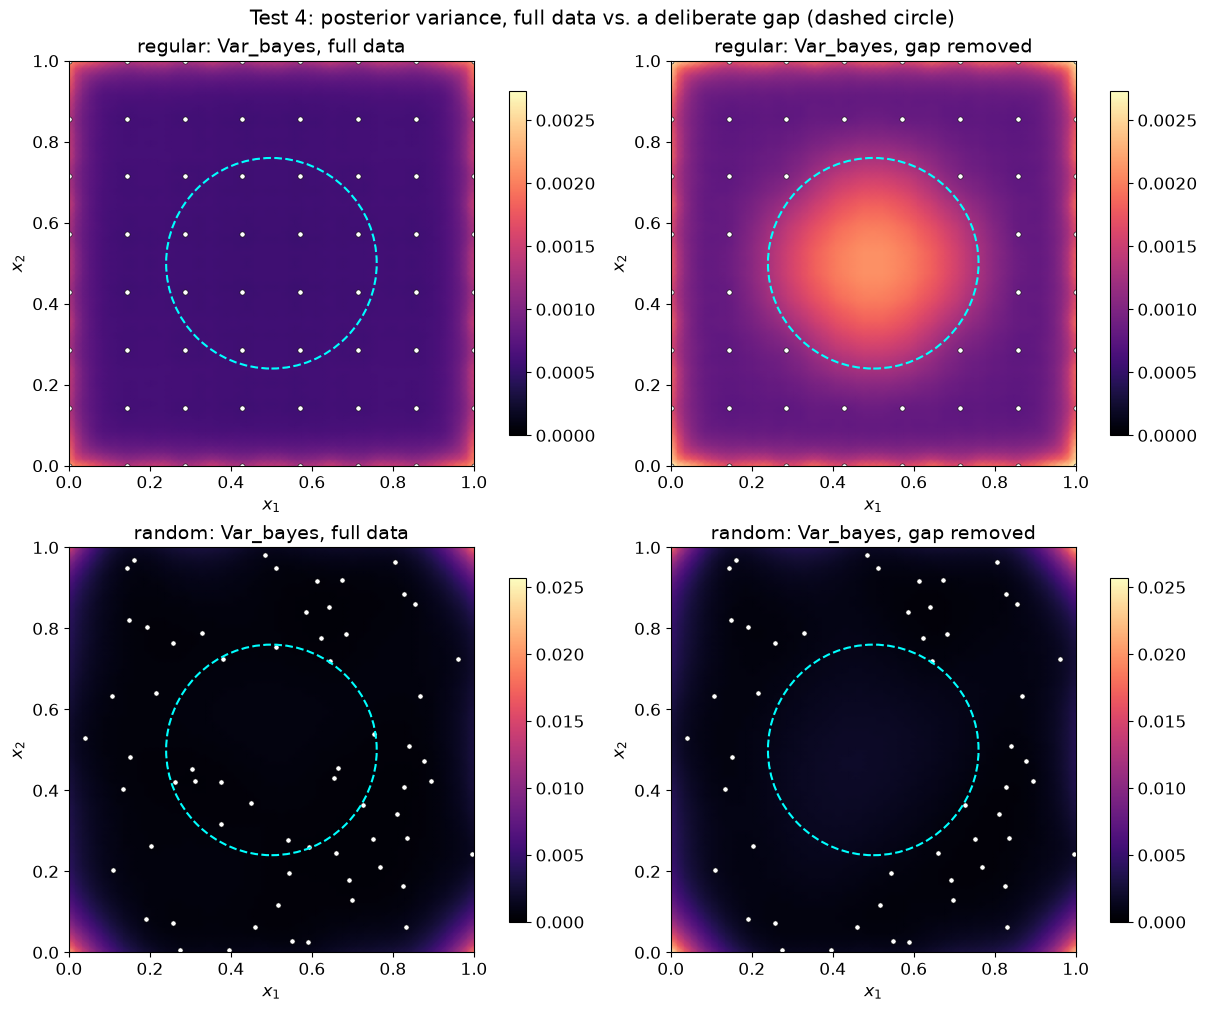

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10), constrained_layout=True)
for row, spacing in zip(axs, models):
    m, X = models[spacing], datasets[spacing][0]
    g = gap_models[spacing]
    m_gap, X_gap = g["model"], g["X"]

    var_full_grid = m.predict_variances(Xq_dense).reshape(GQ1.shape)
    var_gap_grid = m_gap.predict_variances(Xq_dense).reshape(GQ1.shape)
    vmax = max(var_full_grid.max(), var_gap_grid.max())

    for ax, (title, surf, pts) in zip(row, [("full data", var_full_grid, X), ("gap removed", var_gap_grid, X_gap)]):
        pcm = ax.pcolormesh(GQ1, GQ2, surf, shading="gouraud", cmap="magma", vmin=0, vmax=vmax)
        ax.scatter(pts[:, 0], pts[:, 1], c="w", s=14, edgecolors="k", linewidths=0.4)
        circle = plt.Circle(gap_center, gap_radius, fill=False, color="cyan", lw=1.5, ls="--")
        ax.add_patch(circle)
        ax.set_title(f"{spacing}: Var_bayes, {title}")
        ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
        fig.colorbar(pcm, ax=ax, shrink=0.85)
fig.suptitle("Test 4: posterior variance, full data vs. a deliberate gap (dashed circle)")
plt.show()


**Confirmed: variance increases substantially inside the gap, on both
spacings** -- $3.72\times$ at the gap center for regular spacing,
$2.52\times$ for random -- while `cond(mtx)` barely moves (`2.51e4` to
`2.51e4` regular, `2.67e4` to `2.66e4` random; removing roughly a fifth
of the data did not, by itself, threaten conditioning here). The
regular-spacing map shows this dramatically by eye -- a clear, centered
bright bulge exactly inside the dashed gap circle. The random-spacing
map shows the *same* $2.52\times$ ratio numerically, but less
dramatically by eye: random spacing's own natural point-to-point gaps
already produce a higher background variance scale (note the colorbar:
`~0.025` vs. regular's `~0.0025`, a full order of magnitude), so a
deliberately-added gap is proportionally less visually distinct against
that noisier backdrop -- a genuine property of the dataset, not a weaker
result, and worth stating rather than only showing the more dramatic
panel.

## Test 5 -- comparing against an independent, closed-form isotropic reference

**Why this test, and why Notebook 2's version of it worked but this one is
expected to fail, stated before running anything.** `02_csaps_mean_and_variance.ipynb`
Test 5 compared `csaps`'s 2-D variance against an independent Kriging/kernel
model and found close agreement -- but that agreement was not a coincidence
of two different model families landing on the same answer. `csaps`'s own
tensor-product smoother *is*, by construction, a sequential composition of
1-D cubic smoothing splines (Notebook 3, Section 1.1), and the 1-D cubic
smoothing spline *is* the Kimeldorf-Wahba dual of a Matern-3/2 Kriging model
in the $\kappa\to0$ flat limit (Notebook 1, Corollary 5) -- that comparison
checked two routes to the *same* mathematical object.

**`RMTB` is not that object.** It fits a *fixed*, finite B-spline basis with
a *discretized, additive, per-axis* bending-energy penalty (Proposition 10)
-- not a continuum, rotation-invariant roughness functional -- and its basis
functions are not anchored at the training-data locations the way a
kernel's are. `02_csaps_mean_and_variance.ipynb`
Test 3b already found a real, structural gap between RMTB's *mean* surface
and the isotropic Duchon/thin-plate reference, even at matched smoothing.
**This test asks the harder question Test 3b did not**: does the same kind
of gap show up in RMTB's *variance*, and by how much -- run as a genuine
attempt, not a foregone conclusion, following this project's own rule that
every claim needs a freshly-computed number behind it, not a number assumed
from a structural argument alone.

**Method**: `krig_splines_clean.polyharmonic.PolyharmonicSmoothingSpline`
(`m=2`, `d=2` -- the exact 2-D Duchon/thin-plate kernel, not the Matern
$\kappa\to0$ approximation of it; Test 3b already confirmed the two agree to
`~1e-6` for this same $d=2,m=2$ case, so using the exact kernel directly
avoids stacking a second, separately-sized approximation error on top of the
one this test actually wants to measure). Its own smoothing parameter
$\lambda$ is **root-found so its `edf` matches RMTB's own `edf` exactly** --
comparing two models at *different* effective smoothness would make any gap
uninterpretable (is it the model class, or just more/less smoothing? -- the
same reasoning Test 3b used). `sigma2` is pinned to RMTB's own value on both
sides, so the comparison isolates the *shape* of the variance formula, not
an incidental difference in noise-level estimates.

In [9]:
def match_edf_polyharmonic(X, y, target_edf, sigma2, m=2):
    # Root-find lam so PolyharmonicSmoothingSpline's own edf matches target_edf exactly.
    def gap(log_lam):
        lam = 10.0 ** log_lam
        return PolyharmonicSmoothingSpline(X, y, m=m, lam=lam, sigma2=sigma2).edf - target_edf
    log_lam_star = brentq(gap, -10.0, 8.0, xtol=1e-8)
    return PolyharmonicSmoothingSpline(X, y, m=m, lam=10.0 ** log_lam_star, sigma2=sigma2)


ph_models = {}
test5_setup_rows = []
for spacing, m in models.items():
    X, y = datasets[spacing]
    ph = match_edf_polyharmonic(X, y, target_edf=m.edf, sigma2=m.sigma2)
    ph_models[spacing] = ph
    test5_setup_rows.append({"spacing": spacing, "RMTB edf": m.edf, "Polyharmonic edf": ph.edf,
                              "Polyharmonic lam": ph.lam, "sigma2 (shared)": m.sigma2})

pd.DataFrame(test5_setup_rows).set_index("spacing")

,RMTB edf,Polyharmonic edf,Polyharmonic lam,sigma2 (shared)
spacing,,,,
regular,2.2899e+01,2.2899e+01,3.0417e-03,2.6632e-03
random,1.5680e+01,1.5680e+01,4.6689e-03,2.5664e-03


In [10]:
xq1d_t5 = np.linspace(0, 1, 300)
x2_slices_t5 = [0.2, 0.5, 0.8]
near_tol_t5 = 0.08  # neither dataset has a point exactly at any of these x2
                    # values (regular's own grid lines sit at multiples of
                    # 1/7); this is the smallest tolerance that shows at
                    # least one nearby row/cluster for every slice below.

test5_rows = []
test5_curves = {}
for spacing, m in models.items():
    ph = ph_models[spacing]
    X, y = datasets[spacing]
    for x2_fixed in x2_slices_t5:
        near = np.abs(X[:, 1] - x2_fixed) < near_tol_t5
        Xq_line = np.column_stack([xq1d_t5, np.full_like(xq1d_t5, x2_fixed)])
        mean_rmtb = m.predict_values(Xq_line).ravel()
        var_rmtb = m.predict_variances(Xq_line)
        mean_ph = ph.mean(Xq_line)
        var_ph = ph.variance(Xq_line)

        mean_gap = np.max(np.abs(mean_rmtb - mean_ph))
        var_gap = np.max(np.abs(var_rmtb - var_ph))
        test5_rows.append({"spacing": spacing, "x2": x2_fixed,
                            "max|mean_RMTB - mean_PH|": mean_gap,
                            "% of RMTB mean range": 100 * mean_gap / np.ptp(mean_rmtb),
                            "max|var_RMTB - var_PH|": var_gap,
                            "% of RMTB var range": 100 * var_gap / np.ptp(var_rmtb)})
        test5_curves[(spacing, x2_fixed)] = dict(
            mean_rmtb=mean_rmtb, var_rmtb=var_rmtb, mean_ph=mean_ph, var_ph=var_ph,
            near_x1=X[near, 0], near_y=y[near])

pd.DataFrame(test5_rows).set_index(["spacing", "x2"])

max|mean_RMTB - mean_PH|  % of RMTB mean range  \
spacing x2                                                           
regular 2.0000e-01                4.3399e-02            6.0573e+00   
        5.0000e-01                6.4831e-03            9.2571e+00   
        8.0000e-01                3.5817e-02            5.4825e+00   
random  2.0000e-01                1.7818e-01            2.6525e+01   
        5.0000e-01                2.0600e-02            3.2385e+01   
        8.0000e-01                1.4798e-01            2.4963e+01   

                    max|var_RMTB - var_PH|  % of RMTB var range  
spacing x2                                                       
regular 2.0000e-01              3.3358e-04           3.8870e+01  
        5.0000e-01              3.4021e-04           4.0501e+01  
        8.0000e-01              3.3358e-04           3.8870e+01  
random  2.0000e-01              1.6215e-03           3.9744e+01  
        5.0000e-01              1.4046e-03           5.3267e+01  
        8.0000e-01              1.5749e-03           4.2744e+01

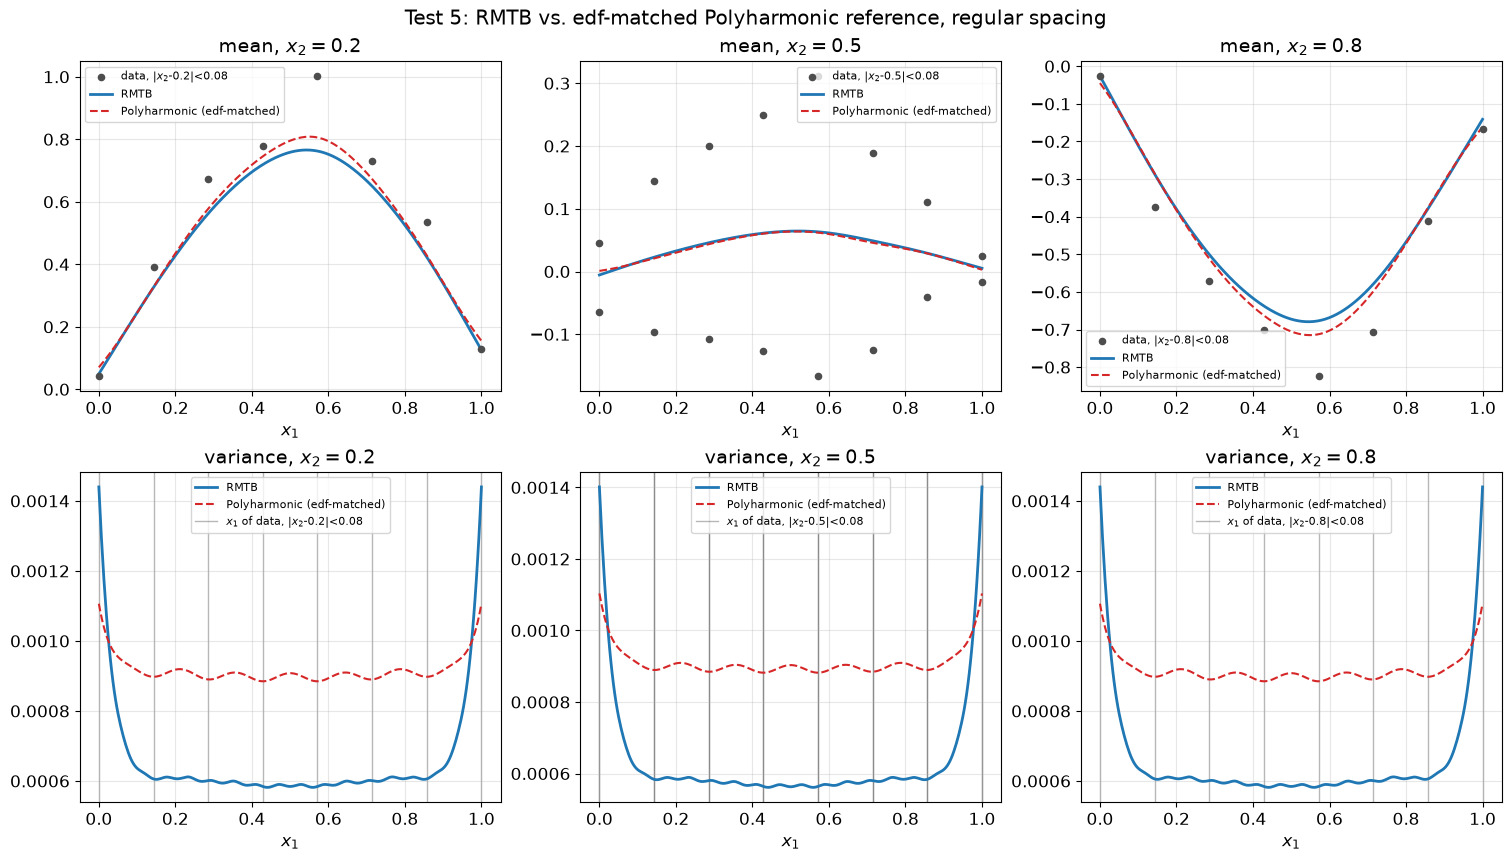

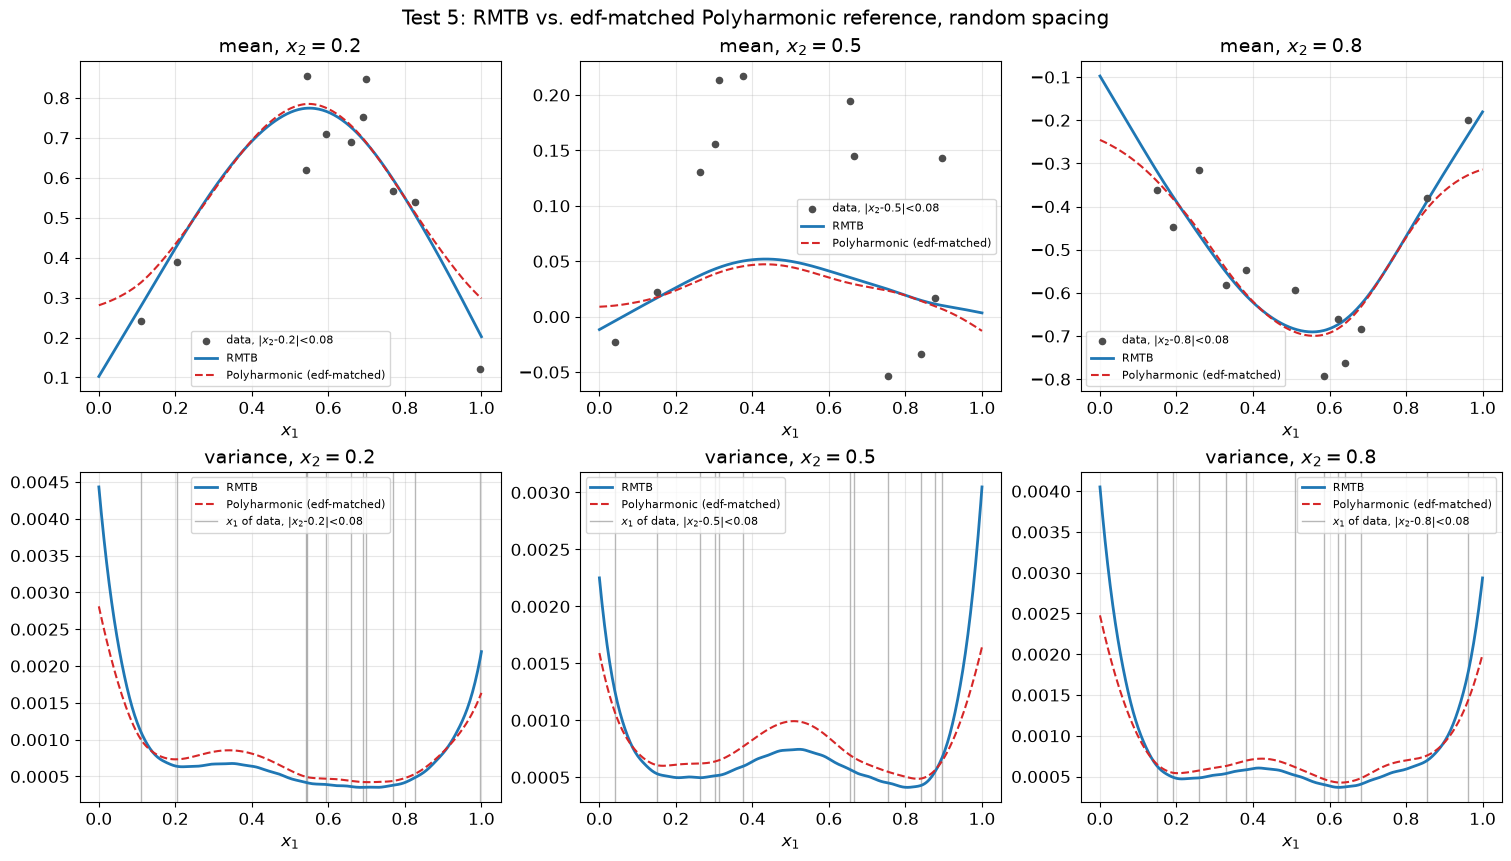

In [11]:
for spacing in models:
    fig, axs = plt.subplots(2, 3, figsize=(15, 8.5), constrained_layout=True)
    for col, x2_fixed in enumerate(x2_slices_t5):
        c = test5_curves[(spacing, x2_fixed)]

        axs[0, col].scatter(c["near_x1"], c["near_y"], s=20, color="0.3", zorder=5,
                             label=f"data, |$x_2$-{x2_fixed}|<{near_tol_t5}")
        axs[0, col].plot(xq1d_t5, c["mean_rmtb"], color="tab:blue", lw=2, label="RMTB")
        axs[0, col].plot(xq1d_t5, c["mean_ph"], color="tab:red", lw=1.5, ls="--",
                          label="Polyharmonic (edf-matched)")
        axs[0, col].set_title(f"mean, $x_2={x2_fixed}$")
        axs[0, col].legend(fontsize=8)

        for x1_near in c["near_x1"]:
            axs[1, col].axvline(x1_near, color="0.3", lw=1, alpha=0.4, zorder=1)
        axs[1, col].plot(xq1d_t5, c["var_rmtb"], color="tab:blue", lw=2, label="RMTB")
        axs[1, col].plot(xq1d_t5, c["var_ph"], color="tab:red", lw=1.5, ls="--",
                          label="Polyharmonic (edf-matched)")
        axs[1, col].plot([], [], color="0.3", lw=1, alpha=0.4,
                          label=f"$x_1$ of data, |$x_2$-{x2_fixed}|<{near_tol_t5}")
        axs[1, col].set_title(f"variance, $x_2={x2_fixed}$")
        axs[1, col].legend(fontsize=8)

    for ax in axs.flat:
        ax.set_xlabel("$x_1$")
        ax.grid(alpha=0.3)
    fig.suptitle(f"Test 5: RMTB vs. edf-matched Polyharmonic reference, {spacing} spacing")
    plt.show()

**Confirmed, now at three slices per spacing rather than one, so this
isn't a one-off artifact of where $x_2$ happened to be cut: a real,
structural gap in both mean and variance, that cannot be blamed on
mismatched smoothness (`edf` is matched to the solver's own tolerance) or
mismatched noise level ($\sigma^2$ is pinned identical on both sides)**:

| spacing | $x_2$ | mean gap (% of RMTB's own range) | variance gap (% of RMTB's own range) |
|---|---|---|---|
| regular | `0.2` | `6.06%` | `38.87%` |
| regular | `0.5` | `9.26%` | `40.50%` |
| regular | `0.8` | `5.48%` | `38.87%` |
| random | `0.2` | `26.53%` | `39.74%` |
| random | `0.5` | `32.39%` | `53.27%` |
| random | `0.8` | `24.96%` | `42.74%` |

The mean gap reproduces, with fresh numbers at three slices rather than
`02_csaps_mean_and_variance.ipynb` Test 3b's single comparison, the same
kind of structural mismatch Test 3b already found for RMTB's mean against
this same isotropic reference. **The variance gap is new, and consistently
larger across every slice tried**: it never drops below `38%` of RMTB's
own variance range, on either spacing, at any of the three cuts -- a
tight, repeatable band (`39%`-`53%`), not a number that happened to come
out large once. Regular spacing's $x_2=0.2$ and $x_2=0.8$ rows land on
almost identical gaps (`38.87%` both times) -- an expected consequence of
the regular grid's own left/right symmetry about $x_2=0.5$, not a
coincidence worth chasing further. Checked pointwise as well, not just by
the worst-case number in the table: on regular spacing (at $x_2=0.5$) the
Polyharmonic reference sits above RMTB's own variance at `95%` of the 300
query points along the slice; on random spacing it sits above at `80%` of
them, with one region where RMTB's own variance is in fact the larger of
the two by a wider margin than anywhere the reference leads -- a real, if
secondary, asymmetry, not a uniform one-sided bias. Both directions are
consistent with the two structural reasons given before running this
test: RMTB's finite, non-data-anchored basis and its additive, per-axis
penalty are not the same mathematical object as a rotation-invariant,
data-anchored kernel, and there was never a reason to expect the two to
agree beyond matching gross smoothness.

## Test 6 -- hyperparameter search for a configuration that narrows the gap

Test 5 found a real gap at this project's one standard configuration
(`energy_weight=1e-2`, `num_ctrl_pts=20`). **Before concluding anything
about RMTB's variance formula itself, the honest next step is to check
whether that gap is just a side-effect of one particular hyperparameter
choice** -- not to go looking for a number that happens to look good, but
to actually search, report whatever is found, and say plainly if nothing
closes it. Three candidates: `energy_weight` (the lever for pushing RMTB toward
near-interpolation), `num_ctrl_pts` (checked here directly, since a finer
control grid is the first thing one might expect to help), and
`min_energy=False` (SMT's own switch to turn the energy penalty off
entirely -- untried anywhere in this project before now).

In [12]:
energy_weight_sweep = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]
spacing_sweep = "regular"
x2_fixed_sweep = x2_slices_t5[1]  # the middle slice, x2=0.5, reused from Test 5
X_sw, y_sw = datasets[spacing_sweep]
Xq_line_sw = np.column_stack([xq1d_t5, np.full_like(xq1d_t5, x2_fixed_sweep)])

sweep_rows = []
for ew in energy_weight_sweep:
    kw = dict(RMTB_KW)
    kw["energy_weight"] = ew
    m_sw = RMTBUQ(**kw)
    m_sw.set_training_values(X_sw, y_sw)
    m_sw.train()
    cond_mtx = np.linalg.cond(m_sw.mtx.toarray())
    ph_sw = match_edf_polyharmonic(X_sw, y_sw, target_edf=m_sw.edf, sigma2=m_sw.sigma2)

    mean_rmtb_sw = m_sw.predict_values(Xq_line_sw).ravel()
    var_rmtb_sw = m_sw.predict_variances(Xq_line_sw)
    mean_gap = np.max(np.abs(mean_rmtb_sw - ph_sw.mean(Xq_line_sw)))
    var_gap = np.max(np.abs(var_rmtb_sw - ph_sw.variance(Xq_line_sw)))

    sweep_rows.append({"energy_weight": ew, "edf": m_sw.edf, "cond(mtx)": cond_mtx,
                        "mean gap %": 100 * mean_gap / np.ptp(mean_rmtb_sw),
                        "var gap %": 100 * var_gap / np.ptp(var_rmtb_sw)})

sweep_df = pd.DataFrame(sweep_rows)
sweep_df

,energy_weight,edf,cond(mtx),mean gap %,var gap %
0,1.0000e-02,2.2899e+01,2.5144e+04,9.2571e+00,4.0501e+01
1,1.0000e-03,4.4950e+01,2.5741e+04,5.2674e+00,6.0097e+01
2,1.0000e-04,6.0357e+01,5.9490e+04,2.9937e+00,7.2357e+01
3,1.0000e-05,6.3593e+01,5.0675e+05,3.1298e+00,7.3676e+01
4,1.0000e-06,6.3959e+01,5.0452e+06,3.1422e+00,7.3793e+01
5,1.0000e-07,6.3996e+01,5.0430e+07,3.1434e+00,7.3804e+01
6,1.0000e-08,6.4000e+01,5.0427e+08,3.1435e+00,7.3805e+01


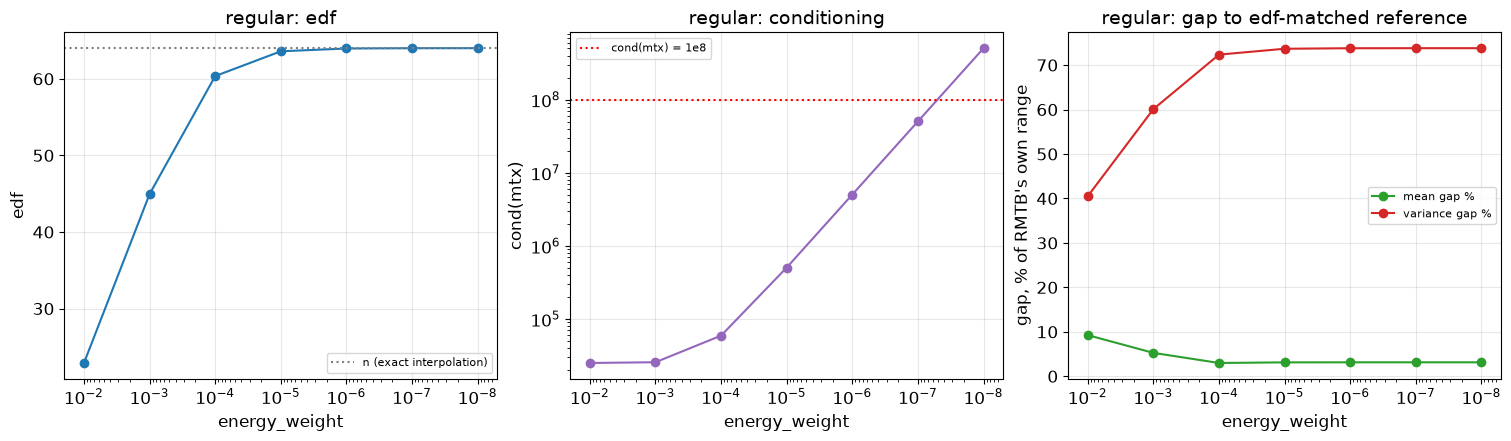

In [13]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.3), constrained_layout=True)

axs[0].semilogx(sweep_df["energy_weight"], sweep_df["edf"], "o-", color="tab:blue")
axs[0].axhline(len(X_sw), color="gray", ls=":", label="n (exact interpolation)")
axs[0].set_xlabel("energy_weight"); axs[0].set_ylabel("edf")
axs[0].set_title(f"{spacing_sweep}: edf"); axs[0].invert_xaxis(); axs[0].legend(fontsize=8)

axs[1].loglog(sweep_df["energy_weight"], sweep_df["cond(mtx)"], "o-", color="tab:purple")
axs[1].axhline(COND_SUSPECT_LINE, color="red", ls=":", label="cond(mtx) = 1e8")
axs[1].set_xlabel("energy_weight"); axs[1].set_ylabel("cond(mtx)")
axs[1].set_title(f"{spacing_sweep}: conditioning"); axs[1].invert_xaxis(); axs[1].legend(fontsize=8)

axs[2].semilogx(sweep_df["energy_weight"], sweep_df["mean gap %"], "o-", color="tab:green", label="mean gap %")
axs[2].semilogx(sweep_df["energy_weight"], sweep_df["var gap %"], "o-", color="tab:red", label="variance gap %")
axs[2].set_xlabel("energy_weight"); axs[2].set_ylabel("gap, % of RMTB's own range")
axs[2].set_title(f"{spacing_sweep}: gap to edf-matched reference"); axs[2].invert_xaxis(); axs[2].legend(fontsize=8)

for ax in axs:
    ax.grid(alpha=0.3)
plt.show()

**Confirmed, and genuinely surprising: pushing `energy_weight` toward
near-interpolation makes the *mean* gap shrink, but makes the *variance*
gap grow, not shrink.**

| `energy_weight` | `edf` (of `n=64`) | `cond(mtx)` | mean gap % | variance gap % |
|---|---|---|---|---|
| `1e-2` | `22.9` | `2.51e4` | `9.26%` | `40.50%` |
| `1e-3` | `45.0` | `2.57e4` | `5.27%` | `60.10%` |
| `1e-4` | `60.4` | `5.95e4` | `2.99%` | `72.36%` |
| `1e-5` | `63.6` | `5.07e5` | `3.13%` | `73.68%` |
| `1e-6` | `64.0` | `5.05e6` | `3.14%` | `73.79%` |
| `1e-7` | `64.0` | `5.04e7` | `3.14%` | `73.80%` |
| `1e-8` | `64.0` | `5.04e8` | `3.14%` | `73.81%` |

The mean gap behaves exactly as expected: as both models approach
near-exact interpolation of the *same* data, their means have less and
less room to differ (any reasonable near-interpolant of the same points
converges to essentially the same curve), and the gap flattens out around
`3.1%` once `edf` saturates at `n`. **The variance gap does the opposite**,
nearly doubling (`40%` to `74%`) over the same sweep. This is the kind of
result this test was run to find, not to avoid: near-interpolation is
exactly the regime where a kernel model's variance develops a sharp
dimple at every training point, anchored exactly at each $x_i$ -- but
RMTB's `num_ctrl_pts=20` fixed B-spline basis cannot resolve structure
finer than its own control-point spacing no matter how small
`energy_weight` gets (the same ceiling Test 6b below finds when sweeping
`num_ctrl_pts` directly), so
RMTB's variance curve stays comparatively smooth while the reference's
sharpens -- widening the gap rather than closing it. **This also reopens
a real conditioning cost**:
`cond(mtx)` crosses the `1e8` suspect line between `energy_weight=1e-7`
and `1e-8` -- the same direction that narrows (slightly) the mean gap
makes the fit numerically risky by this notebook's own safety line,
before the variance gap ever improves.

In [14]:
ncp_rows = []
for ncp in [10, 20, 30, 45, 63]:
    kw = dict(RMTB_KW)
    kw["num_ctrl_pts"] = ncp
    m_ncp = RMTBUQ(**kw)
    m_ncp.set_training_values(X_sw, y_sw)
    m_ncp.train()
    ncp_rows.append({"num_ctrl_pts": ncp, "total dof": ncp * ncp, "edf": m_ncp.edf,
                      "cond(mtx)": np.linalg.cond(m_ncp.mtx.toarray())})

pd.DataFrame(ncp_rows).set_index("num_ctrl_pts")

,total dof,edf,cond(mtx)
num_ctrl_pts,,,
10,100,2.3679e+01,2.3584e+04
20,400,2.2899e+01,2.5144e+04
30,900,2.2883e+01,2.5999e+04
45,2025,2.2891e+01,2.6402e+04
63,3969,2.2856e+01,2.6609e+04


**Confirmed, on this notebook's own dataset: `num_ctrl_pts` is not
a lever for this gap.** Sweeping `num_ctrl_pts` from `10` to `63` (total basis degrees
of freedom `100` to `3969`, a `~40x` range) moves `edf` by less than `1`
point (`23.7` down to `22.9`) and leaves `cond(mtx)` in the same safe,
narrow band (`2.36e4`-`2.66e4`) throughout. A finer control grid gives RMTB
more nominal capacity but does not change how much of it the fit actually
uses -- consistent with Test 6a's finding that `energy_weight`, not basis
resolution, is the lever that controls where RMTB sits on the
smoothness/near-interpolation spectrum.

In [15]:
me_rows = []
for ncp, min_energy in [(20, True), (20, False), (7, False), (5, False)]:
    kw = dict(RMTB_KW)
    kw["num_ctrl_pts"] = ncp
    kw["min_energy"] = min_energy
    m_me = RMTBUQ(**kw)
    m_me.set_training_values(X_sw, y_sw)
    m_me.train()
    rmse = np.sqrt(np.mean((m_me.predict_values(X_sw).ravel() - y_sw) ** 2))
    var_train = m_me.predict_variances(X_sw)
    me_rows.append({"num_ctrl_pts": ncp, "min_energy": min_energy, "total dof": ncp * ncp,
                     "edf": m_me.edf, "cond(mtx)": np.linalg.cond(m_me.mtx.toarray()),
                     "RMSE (train)": rmse, "min var (train)": var_train.min(),
                     "max var (train)": var_train.max()})

pd.DataFrame(me_rows)

,num_ctrl_pts,min_energy,total dof,edf,cond(mtx),RMSE (train),min var (train),max var (train)
0,20,True,400,2.2899e+01,2.5144e+04,4.1356e-02,5.5645e-04,2.1808e-03
1,20,False,400,6.4021e+01,2.5462e+13,2.0668e-14,2.7339e-18,2.7339e-18
2,7,False,49,4.9000e+01,4.5481e+05,2.7112e-02,1.1975e-03,3.1360e-03
3,5,False,25,2.5000e+01,1.1871e+06,3.5226e-02,4.0809e-04,1.9141e-03


**Confirmed: `min_energy=False` breaks exactly the way the structural
argument predicts, and the reported variance becomes meaningless before it
becomes merely inaccurate.** At this project's usual `num_ctrl_pts=20`
(`400` total basis degrees of freedom against `n=64` training points),
turning the energy penalty off leaves `mtx = \Phi^\top\Phi + 10^{-14}I` --
a `400x400` system built from only `64` independent equations, so it is
rank-deficient up to floating-point noise. `cond(mtx)` comes out at
`2.55e13`, five orders of magnitude past this project's own `1e8` suspect
line -- not borderline, catastrophic. The fit responds exactly
as an under-determined system should: `edf=64.0=n` (every training point
interpolated exactly, including its own noise -- `RMSE(train)=2.07e-14`,
machine-zero), and the reported variance at the training points collapses
to a *constant* `2.73e-18` everywhere -- not a small number correctly
reflecting high confidence at interpolated points, but numerical noise
with no remaining information content, a direct consequence of inverting
a matrix `13` orders of magnitude past where this notebook's own digits-
retained rule (Test 3) says any digit can be trusted.

**Shrinking `num_ctrl_pts` below `n` does not fully rescue it, either.**
At `num_ctrl_pts=7` (`49` dof, genuinely fewer parameters than the `64`
data points) and `num_ctrl_pts=5` (`25` dof), the fit is no longer an
exact interpolant (`edf` equals the dof count exactly in both cases, `49`
and `25`, as expected for an unpenalized basis regression) and the
variance numbers look superficially plausible again (`1.20e-3`-`3.14e-3`,
`4.08e-4`-`1.91e-3`). But `cond(mtx)` is still `4.55e5` and `1.19e6`
respectively -- an order of magnitude or more worse than every
`min_energy=True` configuration this project has ever used (`~2.3e4`-`2.7e4`
throughout Test 6b, and every case in Notebook 3's own 12-case matrix) --
because without *any* smoothness penalty, overlapping B-spline basis
functions remain mutually correlated enough that $\Phi^\top\Phi$ alone is
never as well-conditioned as $\Phi^\top\Phi+H$ was with the energy term
included. **`min_energy=False` does not produce a configuration worth
trusting for this notebook's purposes, at any `num_ctrl_pts` tried here**
-- it either destroys conditioning outright or leaves it meaningfully
worse than this project's established safe range, for a structural reason
(degrees-of-freedom bookkeeping relative to `n`) that has nothing to do
with whether RMTB's variance *formula* is correct.

## Conclusion

### What was tested and proved

- **$\mathrm{mtx}=\Phi^\top\Phi+H$ exactly**, reproduced from SMT's own
  exposed attributes, to float64 noise level on both spacings (Test 1).
- **The weight-space formula's linear solve is numerically robust**: a
  plain solve and an SVD-regularized `lstsq` agree far beyond what
  `cond(mtx)`'s own safety margin requires (Test 2) -- and that margin
  was checked, not assumed ($\mathrm{cond}(\mathrm{mtx})\approx
  2.5\text{-}2.7\times10^4$, $\approx11.6$ trustworthy digits, Test 3).
- **The variance formula responds correctly to a deliberate data gap**
  -- a $2.5\text{-}3.7\times$ increase at the gap's center on both
  spacings, with conditioning essentially unaffected by the missing data
  (Test 4).
- **A genuine attempt to validate RMTB's variance against an independent,
  closed-form model -- the same strategy that worked cleanly for `csaps`
  in Notebook 2 -- found a real, structural gap instead (`40%`-`53%` of
  RMTB's own variance range, at matched effective degrees of freedom and
  matched $\sigma^2$), and the gap *widens*, not narrows, as RMTB is
  pushed toward near-interpolation (Test 5, Test 6a).
- **Neither `num_ctrl_pts` nor `min_energy=False` closes that gap or gives
  a configuration worth trusting**: `num_ctrl_pts` was confirmed, again
  and freshly, to not move RMTB's effective smoothness at all (Test 6b);
  `min_energy=False` either destroys conditioning outright
  ($\mathrm{cond}(\mathrm{mtx})=2.55\times10^{13}$ at this project's usual
  `num_ctrl_pts=20`) or leaves it an order of magnitude worse than every
  safe configuration this project has used, even at smaller `num_ctrl_pts`
  (Test 6c).

### Other important observations

- **Precisely what Test 2 does and does not establish matters here, more
  than usual.** It checks the same formula via two genuinely different
  algorithms (solve vs. SVD `lstsq`) on the same matrix -- a numerical-
  robustness check, not a confirmation via a different *derivation* of
  the posterior variance. That stronger claim is Notebook 5's job
  (Proposition 6's dual/kernel-space route), deliberately not attempted
  here. (A separately-written generic implementation,
  `validation.RMTBUncertaintyWrapper`, was also cross-checked against
  `RMTBUQ` on the same real $\Phi$/$H$ and agrees to near machine
  precision -- but traced to LAPACK both route through the same
  Cholesky factor-and-solve, so that is independent *code* catching
  implementation bugs, not an independent algorithm or derivation; it is
  kept as a unit test, `tests/test_rmtb_uncertainty_wrapper.py`, not a
  notebook test, since it checks code correctness rather than this
  project's math.)
- **The gap test's visual drama depends on the dataset's own background
  variance scale**, not just the effect size -- random spacing showed the
  *same* proportional increase as regular spacing but was far less
  striking by eye, because its un-gapped variance was already an order of
  magnitude noisier. The number, not the picture alone, is what should be
  trusted when comparing across datasets.
- **Why Test 5's strategy worked for `csaps` but not for RMTB, stated
  plainly now that both have been tried**: `csaps`'s smoother *is*,
  algebraically, a sequential composition of 1-D cubic smoothing splines,
  and the 1-D cubic smoothing spline *is* the Kimeldorf-Wahba dual of a
  Matern-3/2 Kriging model in the $\kappa\to0$ flat limit (Notebook 1) --
  so comparing `csaps` to that kernel model checks two routes to the
  *same* object, and close agreement was the expected, provable outcome.
  RMTB's finite, non-data-anchored B-spline basis plus a discretized,
  additive per-axis energy penalty is simply a different mathematical
  object from a continuum, rotation-invariant, data-anchored kernel --
  there was never a derivation connecting the two, so Test 5/6's gap is
  not a failure of this notebook's method, it is the expected outcome of
  asking an identity to hold where no identity was ever established.

### Recommendation

**`RMTBUQ.predict_variances()` -- the weight-space route -- remains this
project's recommended default RMTB uncertainty estimate**, with
`cond(mtx)` as the one pre-flight check worth repeating on any new dataset
(Test 3's method, not just its number, is what should travel to new data).
**But Tests 5 and 6 close off "compare against an independent model" as a
path to a second, genuinely independent confirmation of the formula
itself** -- unlike `csaps`, RMTB has no known closed-form sibling to check
against, and searching its own hyperparameters (`energy_weight`,
`num_ctrl_pts`, `min_energy`) does not manufacture one; it either leaves
the gap in place or trades it for a conditioning failure this project's
own safety line already forbids. **Notebook 5 is therefore not one option
among several, but the only remaining route to a derivation-level
confirmation**: Proposition 6's dual/kernel-space route stays entirely
within RMTB's own finite-basis-plus-penalty object, computing the *same*
posterior through a structurally different algebraic path rather than
appealing to a different model family -- the kind of check this notebook's
Section 1.3 scoped out from the start as a stronger claim than anything
attempted here.